In [1]:
# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 2. LOAD DATASET

url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully!")


Dataset Loaded Successfully!


In [2]:
# 2. LOAD DATASET

url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully!")


Dataset Loaded Successfully!


In [3]:


# 3. INITIAL DATA INSPECTION

print("\n--- FIRST FIVE ROWS ---")
print(df.head())

print("\n--- LAST FIVE ROWS ---")
print(df.tail())

print("\n--- DATASET SHAPE ---")
print(df.shape)

print("\n--- DATASET INFORMATION ---")
df.info()

print("\n--- STATISTICAL SUMMARY ---")
print(df.describe())

print("\n--- COLUMN NAMES ---")
print(df.columns)

print("\n--- DATA TYPES ---")
print(df.dtypes)



--- FIRST FIVE ROWS ---
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  year  
0       3750.0    male  2007  
1       3800.0  female  2007  
2       3250.0  female  2007  
3          NaN     NaN  2007  
4       3450.0  female  2007  

--- LAST FIVE ROWS ---
       species island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
339  Chinstrap  Dream            55.8           19.8              207.0   
340  Chinstrap  Dream            43.5           18.1              202.0   
341  Chinstrap  Dream            49.6           18.2              193.0   
342  Chinstrap  Drea

In [4]:

# 4. CHECK MISSING VALUES

print("\n--- MISSING VALUES ---")
print(df.isnull().sum())

print("\n--- MISSING VALUE PERCENTAGE ---")

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

missing_data = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': missing_percentage
})

print("\n--- MISSING VALUE SUMMARY ---")
print(missing_data)




--- MISSING VALUES ---
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

--- MISSING VALUE PERCENTAGE ---
species              0.000000
island               0.000000
bill_length_mm       0.581395
bill_depth_mm        0.581395
flipper_length_mm    0.581395
body_mass_g          0.581395
sex                  3.197674
year                 0.000000
dtype: float64

--- MISSING VALUE SUMMARY ---
                   Missing Values  Missing Percentage
species                         0            0.000000
island                          0            0.000000
bill_length_mm                  2            0.581395
bill_depth_mm                   2            0.581395
flipper_length_mm               2            0.581395
body_mass_g                     2            0.581395
sex                            11            3.197674
year               

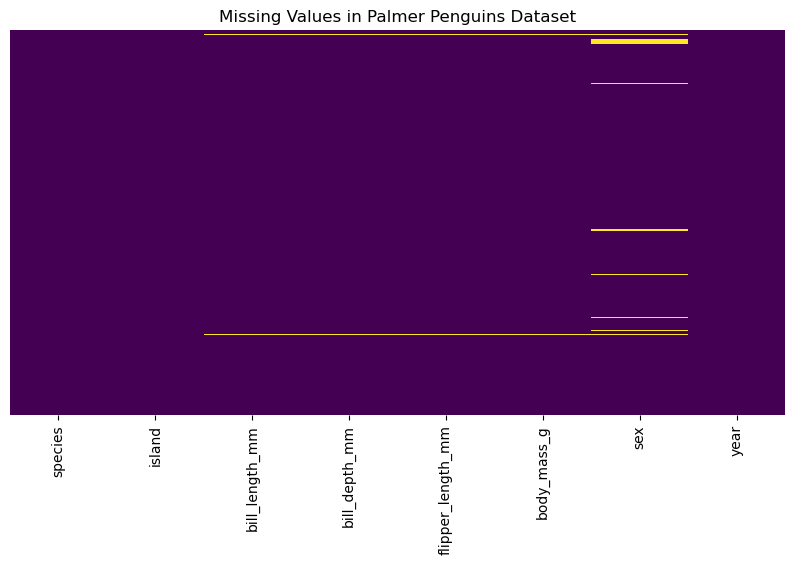

In [5]:
# 5. VISUALIZE MISSING VALUES

plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title("Missing Values in Palmer Penguins Dataset")
plt.show()



In [6]:
# 6. CREATE A CLEANING COPY

df_clean = df.copy()

In [7]:
# 7. IDENTIFY NUMERICAL AND CATEGORICAL COLUMNS

numerical_columns = df_clean.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_columns = df_clean.select_dtypes(
    include=['object']
).columns

print("\nNumerical Columns:", list(numerical_columns))
print("Categorical Columns:", list(categorical_columns))





Numerical Columns: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'year']
Categorical Columns: ['species', 'island', 'sex']


In [8]:
# 8. HANDLE NUMERICAL MISSING VALUES

measurement_columns = [
    'bill_length_mm',
    'bill_depth_mm',
    'flipper_length_mm',
    'body_mass_g'
]

for col in measurement_columns:

    df_clean[col] = df_clean.groupby('species')[col].transform(
        lambda x: x.fillna(x.median())
    )

    # Fallback if any missing values remain
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

In [9]:

# 9. HANDLE CATEGORICAL MISSING VALUES

df_clean['sex'] = df_clean['sex'].fillna('Unknown')



In [10]:
# 10. CHECK MISSING VALUES AGAIN

print("\n--- MISSING VALUES AFTER IMPUTATION ---")
print(df_clean.isnull().sum())



--- MISSING VALUES AFTER IMPUTATION ---
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
year                 0
dtype: int64


In [11]:

# 11. CHECK DUPLICATES

print("\n--- DUPLICATE ROWS ---")
print(df_clean.duplicated().sum())

print("\n--- DUPLICATE RECORDS ---")
print(df_clean[df_clean.duplicated()])



--- DUPLICATE ROWS ---
0

--- DUPLICATE RECORDS ---
Empty DataFrame
Columns: [species, island, bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g, sex, year]
Index: []


In [12]:

# 12. REMOVE EXACT DUPLICATES

df_clean = df_clean.drop_duplicates()


In [13]:

# 13. STANDARDIZE COLUMN NAMES

df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
)



In [14]:
# 14. CLEAN CATEGORICAL VALUES

categorical_clean_columns = ['species', 'island', 'sex']

for col in categorical_clean_columns:

    df_clean[col] = df_clean[col].str.strip()
    df_clean[col] = df_clean[col].str.title()


In [15]:
# 15. CHECK CATEGORICAL VALUES

for col in categorical_clean_columns:

    print(f"\n--- {col.upper()} DISTRIBUTION ---")
    print(df_clean[col].value_counts(dropna=False))



--- SPECIES DISTRIBUTION ---
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

--- ISLAND DISTRIBUTION ---
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

--- SEX DISTRIBUTION ---
sex
Male       168
Female     165
Unknown     11
Name: count, dtype: int64


In [16]:

# 16. DETECT OUTLIERS USING IQR METHOD

print("\n--- OUTLIER DETECTION ---")

outlier_summary = {}

for col in measurement_columns:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    outlier_summary[col] = len(outliers)

    print(f"\nColumn: {col}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Outliers:", len(outliers))




--- OUTLIER DETECTION ---

Column: bill_length_mm
Q1: 39.2
Q3: 48.5
IQR: 9.299999999999997
Lower Bound: 25.250000000000007
Upper Bound: 62.449999999999996
Outliers: 0

Column: bill_depth_mm
Q1: 15.575
Q3: 18.7
IQR: 3.125
Lower Bound: 10.8875
Upper Bound: 23.3875
Outliers: 0

Column: flipper_length_mm
Q1: 190.0
Q3: 213.25
IQR: 23.25
Lower Bound: 155.125
Upper Bound: 248.125
Outliers: 0

Column: body_mass_g
Q1: 3550.0
Q3: 4756.25
IQR: 1206.25
Lower Bound: 1740.625
Upper Bound: 6565.625
Outliers: 0


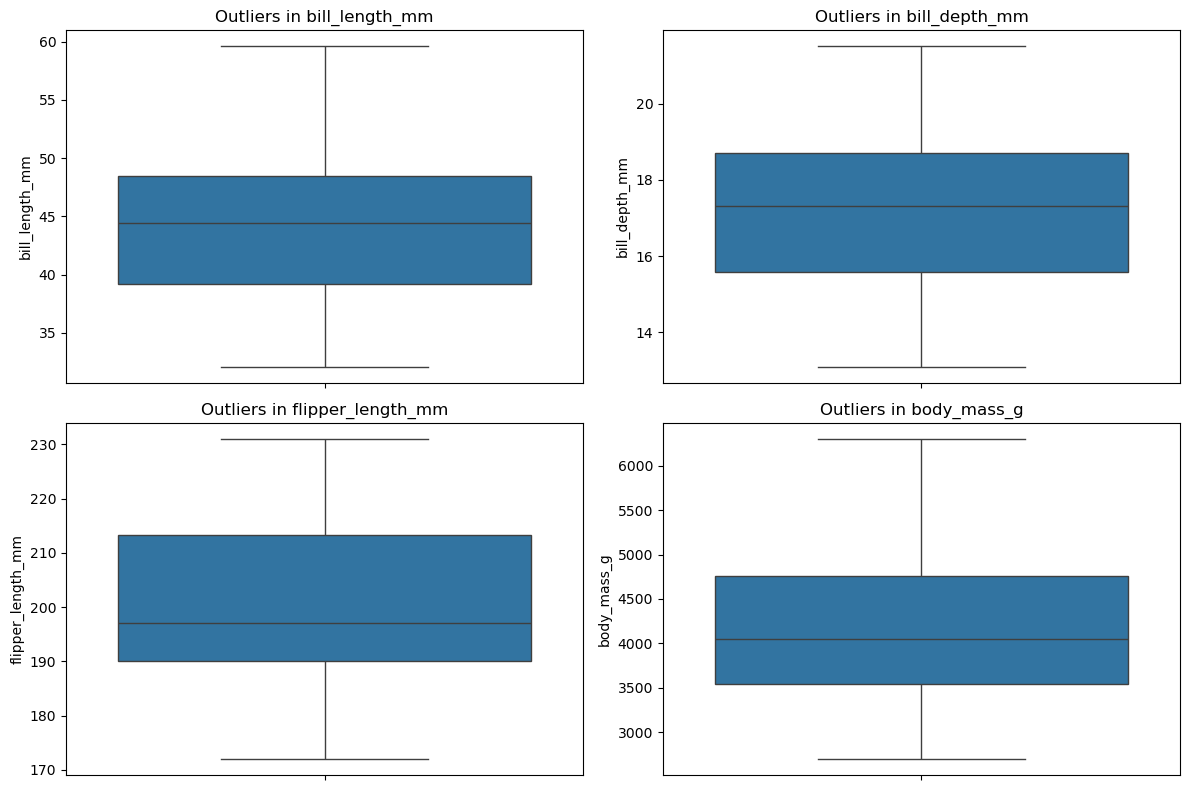

In [17]:

# 17. VISUALIZE OUTLIERS

plt.figure(figsize=(12, 8))

for i, col in enumerate(measurement_columns, 1):

    plt.subplot(2, 2, i)

    sns.boxplot(data=df_clean, y=col)

    plt.title(f"Outliers in {col}")

plt.tight_layout()
plt.show()


In [18]:


# 18. VALIDATE CLEANED DATASET

print("\n--- FINAL DATASET VALIDATION ---")

print("\nOriginal Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nData Types:")
print(df_clean.dtypes)

print("\nStatistical Summary:")
print(df_clean.describe())


--- FINAL DATASET VALIDATION ---

Original Dataset Shape: (344, 8)
Cleaned Dataset Shape: (344, 8)

Missing Values:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
year                 0
dtype: int64

Duplicate Rows:
0

Data Types:
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object

Statistical Summary:
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  \
count      344.000000     344.000000         344.000000   344.000000   
mean        43.916860      17.148547         200.927326  4202.616279   
std          5.453713       1.973601          14.056652   801.231551   
min         32.100000      13.100000         172.000000  2700.000000   
25%         39.200000     

In [19]:

# 19. CHECK CATEGORICAL DISTRIBUTIONS

print("\n--- SPECIES DISTRIBUTION ---")
print(df_clean['species'].value_counts())

print("\n--- ISLAND DISTRIBUTION ---")
print(df_clean['island'].value_counts())

print("\n--- SEX DISTRIBUTION ---")
print(df_clean['sex'].value_counts())



--- SPECIES DISTRIBUTION ---
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

--- ISLAND DISTRIBUTION ---
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

--- SEX DISTRIBUTION ---
sex
Male       168
Female     165
Unknown     11
Name: count, dtype: int64


In [20]:


# 20. COMPARE ORIGINAL AND CLEANED DATASETS

comparison = pd.DataFrame({

    'Original': [
        df.shape[0],
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ],

    'Cleaned': [
        df_clean.shape[0],
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum()
    ]

}, index=[
    'Total Rows',
    'Missing Values',
    'Duplicate Rows'
])

print("\n--- DATA CLEANING COMPARISON ---")
print(comparison)



--- DATA CLEANING COMPARISON ---
                Original  Cleaned
Total Rows           344      344
Missing Values        19        0
Duplicate Rows         0        0


In [21]:


# 21. EXPORT CLEANED DATASET

output_path = "penguins_cleaned.csv"

df_clean.to_csv(output_path, index=False)

print("\nCleaned Dataset Exported Successfully!")




Cleaned Dataset Exported Successfully!


In [22]:
# 22. VERIFY EXPORTED FILE

print("\nFile Exists:", os.path.exists(output_path))
print("File Location:", os.path.abspath(output_path))


# 23. FINAL OUTPUT

print("\n--- FINAL CLEANED DATASET ---")
print(df_clean.head())

print("\n--- CLEANING PROCESS COMPLETED ---")



File Exists: True
File Location: /Users/upendrakumaryadav415/Data Science/Extras/My Practices/03_Palmer_Penguin/penguins_cleaned.csv

--- FINAL CLEANED DATASET ---
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen            38.8           18.4              190.0   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g      sex  year  
0       3750.0     Male  2007  
1       3800.0   Female  2007  
2       3250.0   Female  2007  
3       3700.0  Unknown  2007  
4       3450.0   Female  2007  

--- CLEANING PROCESS COMPLETED ---
